# Notebook 4 - Understand, select, and compare Route 7 models

**Continue from Notebook 3.** Run its final export cell, then put `Route7_Development.csv` beside this notebook. This notebook starts with that dataframe: loading the original workbook, cleaning, and schedule matching are already done.

We first inspect regression statistics, compare predictor groups, demonstrate backward selection, and try one random forest. We finish with results, interpretation, and answered questions about the next route experiment. PCA is omitted.

**Question:** can direction, scheduled hour, and weekday improve arrival-delay predictions beyond the timetable and historical median?

**Scope:** 304 provisional Health Department arrivals in both directions; 232 training records on the first 10 dates and 72 validation records on the next three. Final-test dates are absent from the input. Each day has one recorded bus. This is exploratory development, not independently verified live prediction.

**Prediction information:** scheduled direction/hour/weekday are known in advance. Actual arrival, passenger counts at the target, bus ID, IQR flags, and schedule-audit fields are never predictors. Label verification is retrospective; we make no claim that its matcher could run live using only past data.

Tables and plots are already included. Rerun top to bottom to reproduce them.

## 1. Load the previous dataframe and show the regression summary

We preserve Notebook 3's date split and all its retained observations. The function below converts categories to indicator columns using training data. It adds an intercept and uses the same columns when making predictions. An unseen weekday cannot have its own learned effect; it uses the reference encoding. This occurs in the earliest small training fold.

`GROUPS` means the three original concepts. All weekday indicator columns stay together during selection.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from itertools import combinations
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

arrivals = pd.read_csv("Route7_Development.csv", parse_dates=["service_date", "scheduled_arrival", "actual_arrival"],
                       dtype={"bus_id": "string", "stop_id": "string", "direction_id": "string"})
train = arrivals.loc[arrivals["split"].eq("train")].copy()
validation = arrivals.loc[arrivals["split"].eq("validation")].copy()
GROUPS = ["direction_id", "scheduled_hour", "weekday"]
TARGET = "delay_minutes"
assert len(train) == 232 and len(validation) == 72
assert train.service_date.max() < validation.service_date.min()
assert arrivals.service_date.max() <= pd.Timestamp("2023-03-17")
assert not arrivals[[*GROUPS, TARGET, "service_date"]].isna().any().any()
assert arrivals.source_row.is_unique
assert np.allclose(arrivals[TARGET], (arrivals.actual_arrival - arrivals.scheduled_arrival).dt.total_seconds() / 60)
print("Training:", len(train), "records on", train.service_date.nunique(), "days")
print("Validation:", len(validation), "records on", validation.service_date.nunique(), "days")
display(arrivals[["service_date", "bus_id", *GROUPS, TARGET]].head())

def design(training, evaluation, groups):
    if not groups:
        return pd.DataFrame({"const": 1.0}, index=training.index), pd.DataFrame({"const": 1.0}, index=evaluation.index)
    a, b = training[list(groups)].copy(), evaluation[list(groups)].copy()
    categories = [g for g in groups if g in ["direction_id", "weekday"]]
    for g in categories:
        levels = sorted(a[g].dropna().unique())
        a[g] = pd.Categorical(a[g], categories=levels)
        b[g] = pd.Categorical(b[g], categories=levels)
    a = pd.get_dummies(a, columns=categories, drop_first=True, dtype=float)
    b = pd.get_dummies(b, columns=categories, drop_first=True, dtype=float)
    b = b.reindex(columns=a.columns, fill_value=0)
    return sm.add_constant(a.astype(float), has_constant="add"), sm.add_constant(b.astype(float), has_constant="add")

def fit_ols(training, groups):
    x, _ = design(training, training, groups)
    return sm.OLS(training[TARGET].astype(float), x).fit()

def ols_predict(training, evaluation, groups):
    fitted = fit_ols(training, groups)
    _, x = design(training, evaluation, groups)
    return fitted.predict(x).to_numpy()

full_model = fit_ols(train, GROUPS)
print(full_model.summary())

Training: 232 records on 10 days
Validation: 72 records on 3 days
                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.418
Model:                            OLS   Adj. R-squared:                  0.403
Method:                 Least Squares   F-statistic:                     26.94
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           4.13e-24
Time:                        10:11:06   Log-Likelihood:                -477.63
No. Observations:                 232   AIC:                             969.3
Df Residuals:                     225   BIC:                             993.4
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

,service_date,bus_id,direction_id,scheduled_hour,weekday,delay_minutes
0,2023-03-01,2105,0,6,Wednesday,5.333333
1,2023-03-01,2105,1,6,Wednesday,1.200000
2,2023-03-01,2105,0,7,Wednesday,7.983333
3,2023-03-01,2105,1,7,Wednesday,0.950000
4,2023-03-01,2105,0,8,Wednesday,5.983333


### How to read the summary

| Statistic | Meaning here | How to use it |
|---|---|---|
| Coefficient | Estimated difference in delay, in minutes, holding included inputs fixed | Compare with its confidence interval; association is not causation |
| Intercept | Predicted delay for reference categories at hour zero | Hour zero is outside service hours, so this is a mathematical anchor |
| Standard error / confidence interval | Uncertainty under the model's assumptions | Wide intervals mean uncertain effects |
| P-value | Evidence against a zero coefficient under those assumptions | Not a measure of prediction quality or effect importance |
| R² / adjusted R² | Training variance explained; adjusted R² penalizes extra terms | Neither is an unseen-date accuracy score |
| F-statistic / Prob(F) | Classical joint test against an intercept-only linear model | This is a regression F-statistic, not classification F1 |
| AIC / BIC | Training fit balanced against parameter count | Lower is preferred only for the same response and observations |

Category coefficients are relative to the omitted reference level. Hour has one linear slope: this does not capture separate morning/evening peaks automatically.

**Dependence caution:** repeated observations from a day are not independent. The ordinary summary's p-values/F-test assume the usual OLS covariance model. We also show a day-clustered uncertainty check below, but 10 training days is a small number of clusters. Neither set of p-values should be treated as definitive significance evidence after feature selection.

In [2]:
clustered = full_model.get_robustcov_results(cov_type="cluster", groups=train.service_date, use_correction=True)
uncertainty = pd.DataFrame({"coefficient_minutes": full_model.params,
    "ordinary_p_value": full_model.pvalues,
    "day_clustered_standard_error": clustered.bse,
    "day_clustered_p_value": clustered.pvalues})
display(uncertainty.round(4))
print("Training design rank:", np.linalg.matrix_rank(full_model.model.exog), "/", full_model.model.exog.shape[1])

Training design rank: 7 / 7


,coefficient_minutes,ordinary_p_value,day_clustered_standard_error,day_clustered_p_value
const,6.2076,0.0000,0.4390,0.0000
scheduled_hour,-0.1248,0.0010,0.0406,0.0133
direction_id_1,-3.0444,0.0000,0.3323,0.0000
weekday_Monday,-0.6147,0.1342,0.2037,0.0145
weekday_Thursday,-0.1085,0.7899,0.0917,0.2671
weekday_Tuesday,-0.6330,0.1231,0.4588,0.2010
weekday_Wednesday,0.0071,0.9861,0.1340,0.9589


## 2. Compare the small set of possible predictor combinations

With three predictor groups there are only eight subsets, including an intercept-only model. Showing all eight makes the trade-offs transparent. We are not searching hundreds of features.

The table's R², F-statistic, AIC, and BIC use the same 232 training records. Its prediction error uses expanding **training-date folds**: train on the first 4/6/8 dates, then evaluate on the next two dates. No validation dates participate. Every fold fits its own encoding and regression. The first four dates do not cover all weekdays.

The subset table is exploratory. Picking its lowest fold error and reporting that same error as an independent test would be optimistic. Later we evaluate the complete backward-selection procedure separately inside each fold.

In [3]:
training_dates = sorted(train.service_date.unique())
folds = []
for end in [4, 6, 8]:
    a = train.loc[train.service_date.isin(training_dates[:end])].copy()
    b = train.loc[train.service_date.isin(training_dates[end:end+2])].copy()
    assert a.service_date.max() < b.service_date.min()
    folds.append((a, b))

def fold_mae(groups):
    errors = []
    for a, b in folds:
        errors.extend(np.abs(b[TARGET].to_numpy() - ols_predict(a, b, groups)))
    return float(np.mean(errors))

subsets = [list(c) for size in range(4) for c in combinations(GROUPS, size)]
rows = []
for groups in subsets:
    fitted = fit_ols(train, groups)
    rows.append({"predictors": " + ".join(groups) or "Intercept only", "parameters": len(fitted.params),
        "training_R2": fitted.rsquared, "adjusted_R2": fitted.rsquared_adj,
        "F_statistic": fitted.fvalue, "F_p_value": fitted.f_pvalue,
        "AIC": fitted.aic, "BIC": fitted.bic, "training_fold_MAE_minutes": fold_mae(groups)})
subset_results = pd.DataFrame(rows)
display(subset_results.round(4))

,predictors,parameters,training_R2,adjusted_R2,F_statistic,F_p_value,AIC,BIC,training_fold_MAE_minutes
0,Intercept only,1,0.0000,0.0000,NaN,nan,1082.8645,1086.3113,2.0365
1,direction_id,2,0.3744,0.3717,137.6392,0.0,976.0513,982.9447,1.6522
2,scheduled_hour,2,0.0278,0.0235,6.5664,0.01103,1078.3338,1085.2272,2.0206
3,weekday,5,0.0163,-0.0010,0.9416,0.440595,1087.0465,1104.2802,2.0516
4,direction_id + scheduled_hour,3,0.4043,0.3991,77.6976,0.0,966.7003,977.0405,1.6247
5,direction_id + weekday,6,0.3891,0.3756,28.7936,0.0,978.5162,999.1966,1.6603
6,scheduled_hour + weekday,6,0.0431,0.0219,2.0363,0.074542,1082.6412,1103.3217,2.0303
7,direction_id + scheduled_hour + weekday,7,0.4180,0.4025,26.9380,0.0,969.2683,993.3954,1.6317


## 3. Backward selection using AIC

Start with all three groups. Remove each possible group in turn, fit the remaining groups on the same training records, and keep the removal giving the lowest AIC **only if AIC decreases**. Repeat until no removal helps.

Weekday is removed as a whole group. We do not delete individual weekday indicators based on isolated p-values. AIC balances likelihood and complexity, while BIC penalizes extra parameters more strongly at this sample size. Neither guarantees lower future-date MAE.

The next cell records both the candidate removals and the accepted path. Selection is performed again from scratch inside each fold later; a subset chosen using all training dates must not be carried backward into earlier folds.

In [4]:
def backward_aic(training):
    kept = list(GROUPS)
    path, candidates = [], []
    step = 0
    while True:
        current = fit_ols(training, kept)
        path.append({"step": step, "predictors": " + ".join(kept) or "Intercept only", "AIC": current.aic, "BIC": current.bic})
        options = []
        for dropped in kept:
            trial = [g for g in kept if g != dropped]
            fitted = fit_ols(training, trial)
            options.append((fitted.aic, dropped, trial))
            candidates.append({"step": step, "remove": dropped, "remaining": " + ".join(trial) or "Intercept only", "AIC": fitted.aic})
        if not options:
            break
        best_aic, dropped, trial = min(options, key=lambda item: item[0])
        if best_aic >= current.aic - 1e-8:
            break
        kept, step = trial, step + 1
    return kept, pd.DataFrame(path), pd.DataFrame(candidates)

selected_groups, selection_path, removal_candidates = backward_aic(train)
display(removal_candidates.round(3))
display(selection_path.round(3))
selected_model = fit_ols(train, selected_groups)
print("Groups retained:", selected_groups)
print(selected_model.summary())

Groups retained: ['direction_id', 'scheduled_hour']
                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.404
Model:                            OLS   Adj. R-squared:                  0.399
Method:                 Least Squares   F-statistic:                     77.70
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.75e-26
Time:                        10:11:07   Log-Likelihood:                -480.35
No. Observations:                 232   AIC:                             966.7
Df Residuals:                     229   BIC:                             977.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

,step,remove,remaining,AIC
0,0,direction_id,scheduled_hour + weekday,1082.641
1,0,scheduled_hour,direction_id + weekday,978.516
2,0,weekday,direction_id + scheduled_hour,966.700
3,1,direction_id,scheduled_hour,1078.334
4,1,scheduled_hour,direction_id,976.051


,step,predictors,AIC,BIC
0,0,direction_id + scheduled_hour + weekday,969.268,993.395
1,1,direction_id + scheduled_hour,966.700,977.040


## 4. Compare the procedures and one random forest

A forest can learn nonlinear hour effects and interactions. We use one modest, fixed configuration: 300 trees, maximum depth 4, and at least 10 observations per leaf. We do not tune it against validation.

All procedures use identical date folds and target observations. Backward selection runs **inside each fold's training portion**. We compare against the schedule and historical median. The intercept-only OLS from the earlier table predicts the mean, which differs from the median.

Ordinary OLS coefficient p-values, F-statistics, AIC, and BIC are not directly available/comparable for this forest. Compare predictive errors across model families instead. We keep PCA out because three interpretable predictor groups do not justify it.

In [5]:
def forest():
    encoder = ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["direction_id", "weekday"]),
        ("hour", "passthrough", ["scheduled_hour"])])
    return Pipeline([("encode", encoder), ("model", RandomForestRegressor(
        n_estimators=300, max_depth=4, min_samples_leaf=10, random_state=42, n_jobs=1))])

def predict_procedure(name, training, evaluation):
    if name == "Published schedule": return np.zeros(len(evaluation)), "none"
    if name == "Historical median": return np.repeat(training[TARGET].median(), len(evaluation)), "none"
    if name == "Full linear regression": return ols_predict(training, evaluation, GROUPS), ", ".join(GROUPS)
    if name == "Backward AIC regression":
        groups, _, _ = backward_aic(training)
        return ols_predict(training, evaluation, groups), ", ".join(groups) or "intercept"
    fitted = forest().fit(training[GROUPS], training[TARGET])
    return fitted.predict(evaluation[GROUPS]), ", ".join(GROUPS)

METHODS = ["Published schedule", "Historical median", "Full linear regression", "Backward AIC regression", "Random forest"]
fold_scores, fold_predictions = [], []
for fold_number, (a, b) in enumerate(folds, start=1):
    for name in METHODS:
        predicted, used = predict_procedure(name, a, b)
        errors = b[TARGET].to_numpy() - predicted
        fold_scores.append({"fold": fold_number, "method": name, "training_rows": len(a), "evaluation_rows": len(b),
            "predictors": used, "MAE_minutes": np.abs(errors).mean()})
        for row_id, error in zip(b.source_row, errors):
            fold_predictions.append({"source_row": row_id, "method": name, "absolute_error": abs(error), "squared_error": error**2})
fold_scores = pd.DataFrame(fold_scores)
oof = pd.DataFrame(fold_predictions)
procedure_scores = oof.groupby("method").agg(records=("absolute_error", "size"), MAE_minutes=("absolute_error", "mean"), MSE=("squared_error", "mean"))
procedure_scores["RMSE_minutes"] = np.sqrt(procedure_scores.pop("MSE"))
procedure_scores = procedure_scores.sort_values("MAE_minutes")
chosen_procedure = procedure_scores.index[0]
display(fold_scores.round(3))
display(procedure_scores.round(4))
print("Procedure chosen using training folds only:", chosen_procedure)

Procedure chosen using training folds only: Random forest


,fold,method,training_rows,evaluation_rows,predictors,MAE_minutes
0,1,Published schedule,92,48,none,3.381
1,1,Historical median,92,48,none,1.969
2,1,Full linear regression,92,48,"direction_id, scheduled_hour, weekday",1.339
3,1,Backward AIC regression,92,48,"direction_id, scheduled_hour",1.376
4,1,Random forest,92,48,"direction_id, scheduled_hour, weekday",1.352
5,2,Published schedule,140,46,none,3.314
6,2,Historical median,140,46,none,2.066
7,2,Full linear regression,140,46,"direction_id, scheduled_hour, weekday",1.433
8,2,Backward AIC regression,140,46,"direction_id, scheduled_hour",1.426
9,2,Random forest,140,46,"direction_id, scheduled_hour, weekday",1.329


,records,MAE_minutes,RMSE_minutes
method,,,
Random forest,140,1.5912,2.1016
Backward AIC regression,140,1.6247,2.1384
Full linear regression,140,1.6317,2.1425
Historical median,140,1.9770,2.5734
Published schedule,140,3.1312,3.9230


## 5. Refit, report validation errors, and convert delay to arrival time

The training-fold choice is recorded before reading validation outcomes. We refit each fixed procedure on all 232 training observations, then describe performance on the same 72 later observations. Showing all methods helps explain the experiment; do not switch the selected method just because another wins this table.

These validation dates have been inspected in previous work. This is an exploratory replication, not a fresh confirmatory evaluation. The final-test dates are still absent and unscored.

**Predicted arrival = scheduled arrival + predicted delay.** MAE is minutes, not a percentage accuracy.

,method,chosen_by_training_folds,MAE_minutes,RMSE_minutes,validation_R2
0,Published schedule,False,2.7120,3.5833,-0.9748
1,Historical median,False,1.6333,2.5501,-0.0002
2,Full linear regression,False,2.0821,2.6521,-0.0818
3,Backward AIC regression,False,2.0271,2.6163,-0.0528
4,Random forest,True,2.1521,2.7655,-0.1763


,service_date,scheduled_arrival,actual_arrival,predicted_arrival,absolute_error_minutes
232,2023-03-15,2023-03-15 06:08:00,2023-03-15 06:16:06,2023-03-15 06:12:36.301908126,3.494968
233,2023-03-15,2023-03-15 06:40:00,2023-03-15 06:45:06,2023-03-15 06:42:00.423839490,3.092936
234,2023-03-15,2023-03-15 07:08:00,2023-03-15 07:11:24,2023-03-15 07:12:36.301908126,1.205032
235,2023-03-15,2023-03-15 07:40:00,2023-03-15 07:43:30,2023-03-15 07:42:00.423839490,1.492936
236,2023-03-15,2023-03-15 08:08:00,2023-03-15 08:10:09,2023-03-15 08:13:14.334823038,3.088914
237,2023-03-15,2023-03-15 08:40:00,2023-03-15 08:40:48,2023-03-15 08:41:27.752971464,0.662550
238,2023-03-15,2023-03-15 09:08:00,2023-03-15 09:10:07,2023-03-15 09:13:16.919982546,3.165333
239,2023-03-15,2023-03-15 09:40:00,2023-03-15 09:42:03,2023-03-15 09:41:28.991594076,0.566807


,size,MAE_minutes
service_date,,
2023-03-15,24,1.927
2023-03-16,24,2.381
2023-03-17,24,2.148


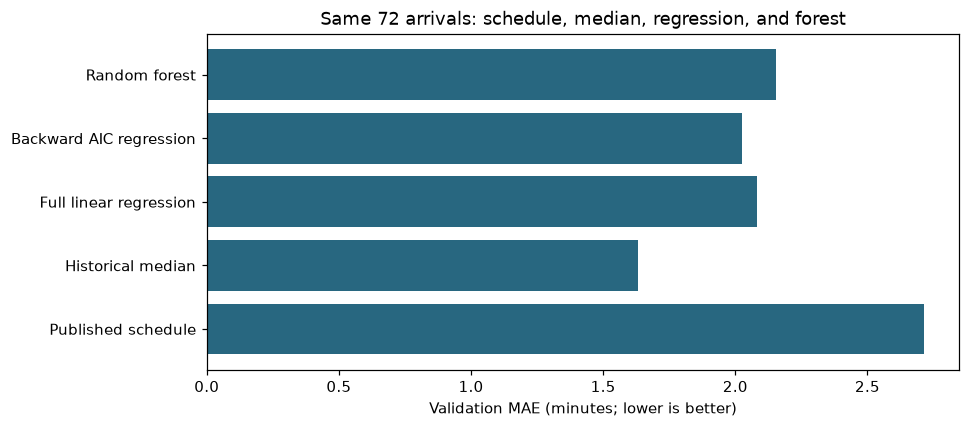

In [6]:
validation_rows = []
validation_predictions = validation[["source_row", "service_date", "bus_id", "direction_id", "scheduled_arrival", "actual_arrival", TARGET]].copy()
for name in METHODS:
    predicted, used = predict_procedure(name, train, validation)
    validation_predictions[name] = predicted
    validation_rows.append({"method": name, "chosen_by_training_folds": name == chosen_procedure,
        "MAE_minutes": mean_absolute_error(validation[TARGET], predicted),
        "RMSE_minutes": np.sqrt(mean_squared_error(validation[TARGET], predicted)),
        "validation_R2": r2_score(validation[TARGET], predicted)})
validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))
validation_predictions["predicted_arrival"] = validation_predictions.scheduled_arrival + pd.to_timedelta(validation_predictions[chosen_procedure], unit="min")
validation_predictions["absolute_error_minutes"] = (validation_predictions[chosen_procedure] - validation[TARGET]).abs()
display(validation_predictions[["service_date", "scheduled_arrival", "actual_arrival", "predicted_arrival", "absolute_error_minutes"]].head(8))
display(validation_predictions.groupby("service_date").absolute_error_minutes.agg(["size", "mean"]).rename(columns={"mean": "MAE_minutes"}).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(validation_results.method, validation_results.MAE_minutes, color="#286780")
ax.set(xlabel="Validation MAE (minutes; lower is better)", title="Same 72 arrivals: schedule, median, regression, and forest")
fig.tight_layout()
plt.show()

## 6. Results explained - answers for the research group

### What did the regression statistics tell us?
The full model explains **41.8%** of training delay variation (adjusted R² **0.403**). Its classical F-statistic is **26.94**, with p-value **4.13e-24**. This is evidence of an association under the ordinary regression assumptions, not proof of accurate future arrivals or a causal effect. Within-day dependence and only ten training days limit significance claims. Use the day-clustered table as a sensitivity check, not a guarantee.

The full model has AIC **969.27** and BIC **993.40**. The lowest-AIC subset is **direction_id + scheduled_hour**; the lowest-BIC subset is **direction_id + scheduled_hour**. AIC/BIC values are relative rankings for these same training observations, not error in minutes.

### Which features did backward selection retain?
**direction_id, scheduled_hour**. The selected regression has AIC **966.70** and BIC **977.04**. Features can help training likelihood without improving absolute error on later dates.

### Did selection improve prediction?
Full regression training-fold MAE: **1.632 minutes**. Backward-selection procedure MAE: **1.625 minutes**. These evaluate procedures on identical 140 out-of-fold observations, with selection redone inside each training fold. Their validation MAEs are **2.082** and **2.027 minutes** respectively. Read both comparisons before claiming a benefit.

### Did the forest beat the simple baseline?
Forest MAE is **1.591 minutes** on training-date folds and **2.152 minutes** on validation. The historical median scores **1.977** and **1.633 minutes**, respectively. A forest is not automatically better because it is more flexible; predictive comparisons decide.

### Which approach should we call best?
The predeclared lowest training-fold MAE rule chose **Random forest**. The lowest validation MAE belongs to **Historical median**. If these disagree, report instability rather than replacing the selection rule after seeing validation. Repeated inspection and three validation dates prevent a definitive winner claim.

### Is this better than the published schedule?
Schedule MAE is **2.712 minutes**. Median MAE is **1.633 minutes**, a **39.8% reduction** in validation MAE. This compares with the published timetable, not Navigator's live estimate. The percentage is error reduction, not classification accuracy.

### Why leave PCA out?
Direction, hour, and weekday are already few and interpretable. PCA would mix their encoded columns into components, making the research explanation harder without a demonstrated need.

### What remains before a final claim?
Verify provisional schedule links, freeze the complete label/feature/model-selection rules, fit the frozen approach on approved development data, and evaluate the held-out final dates once. Do not choose outlier rules or feature sets using those final outcomes. No final-test score appears here.

### What should we take away from these numbers?

- **Weekday was removed:** its additional training fit did not offset the extra indicator coefficients under AIC. This does not prove weekday never matters; there are only ten training days.
- **Selection mainly simplified the explanation:** validation MAE improved by about 0.055 minutes, or **3.3 seconds**. That is a small change, not a major predictive improvement. The backward procedure's training-fold gain is also less than one second of MAE.
- **Direction is associated with training delay:** direction 1 is about 3.04 minutes earlier relative to schedule than direction 0, conditional on hour and weekday. This relationship weakened on later dates in earlier diagnostics; do not assume it is stable.
- **The hour effect is modest and linear:** about -0.125 minutes, or **7.5 seconds less delay per hour later**, holding other inputs fixed. That is an association over the observed service hours, not a forecast outside them.
- **The forest did not establish a better solution:** its training-fold MAE beats full regression by only about 2.5 seconds, while its later validation MAE is worse than the median by about **31 seconds**. Three days are too few to identify a dependable generalization winner.
- **A defensible result is still valuable:** simpler models can be competitive. Report the training-fold selection and the validation disagreement, preserve the median baseline, and avoid claiming improvement from additional complexity.


### How large are the estimated effects?

- Per hour later in the schedule, the fitted delay changes by **-0.125 minutes**, holding other inputs fixed (ordinary 95% interval -0.198 to -0.051).
- For `direction_id_1`, compared with its omitted reference category, fitted delay differs by **-3.044 minutes**, holding other inputs fixed (ordinary 95% interval -3.543 to -2.546).
- For `weekday_Monday`, compared with its omitted reference category, fitted delay differs by **-0.615 minutes**, holding other inputs fixed (ordinary 95% interval -1.421 to +0.191).
- For `weekday_Thursday`, compared with its omitted reference category, fitted delay differs by **-0.109 minutes**, holding other inputs fixed (ordinary 95% interval -0.910 to +0.693).
- For `weekday_Tuesday`, compared with its omitted reference category, fitted delay differs by **-0.633 minutes**, holding other inputs fixed (ordinary 95% interval -1.439 to +0.173).
- For `weekday_Wednesday`, compared with its omitted reference category, fitted delay differs by **+0.007 minutes**, holding other inputs fixed (ordinary 95% interval -0.795 to +0.809).

These intervals assume ordinary OLS errors. The clustered uncertainty table above may differ. This is a linear association, not a statement that changing the hour or weekday causes a delay. Stop ID is constant, so its effect cannot be estimated here. Bus ID and actual-arrival-derived audit fields are excluded.

Here the reference direction is 0 and the reference weekday is Friday (alphabetically first among observed training levels). Read the indicator coefficients relative to those levels.

## 7. Questions about other routes - with suggested answers

**1. Should we train each new route separately or combine routes immediately?**  
Start separately to verify its schedule links and establish its own schedule/median/regression baselines. Pool later as an explicit experiment if records and targets are compatible.

**2. Which features should carry over?**  
Direction, scheduled hour, and weekday are a transparent starting point, not universally proven winners. Re-estimate and repeat training-only selection for each route. Add route/stop identifiers if pooling, with direction interpreted within route.

**3. Should we carry over the same coefficients or chosen subset?**  
No. Operating patterns and reference categories may differ. Carry over the procedure and reporting format, then fit using that route's training data.

**4. How should we compare routes fairly?**  
Use the same calendar-date train/validation/test boundaries where dates overlap, and report sample counts, MAE, and baseline improvements per route. If dates do not overlap, disclose that differing periods limit a direct comparison.

**5. When should we prefer a random forest?**  
When it produces a consistent, material improvement over simple baselines on whole-date folds and later evaluation, not merely a better training fit. This small experiment does not justify assuming forests will win on every route.

**6. Do small p-values mean we should keep a feature?**  
Not by themselves. Consider practical effect size, uncertainty, redundancy, availability at prediction time, and future-date error. Selection changes the interpretation of p-values; do not treat post-selection significance as confirmatory.

**7. Can we add passenger counts or recent bus delay next?**  
Only when the exact prediction time is defined and the information was available before it. Passenger counts recorded at the arrival being predicted reveal future information. Recent delay also needs a schedule assignment that can be established without later observations.

**8. What is a defensible undergraduate conclusion?**  
A simple historical-delay correction can improve on the timetable in this scoped sample. Feature selection and a forest test whether complexity adds value; a baseline win is informative. Findings remain limited by provisional linkage, one stop, few dates, and a previously inspected validation set.

**9. What should the group do next?**  
Document the feature-selection decision and limitations, resolve schedule-label concerns, and prepare the frozen final evaluation. Then repeat the pipeline on one additional route before attempting pooling.


## Optional: save the result tables

Uncomment to save new outputs beside this notebook. The dataframe from Notebook 3 remains unchanged.

In [7]:
# subset_results.to_csv("Route7_Feature_Subsets.csv", index=False)
# selection_path.to_csv("Route7_Backward_AIC_Path.csv", index=False)
# procedure_scores.to_csv("Route7_Training_Fold_Comparison.csv")
# validation_results.to_csv("Route7_Feature_Validation.csv", index=False)